# Genetic Algorithm Experiment

**Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis**

- Dataset: SST-2 | Model: Qwen2.5-1.5B-Instruct | Metric: Macro F1
- The GA optimizes natural-language prompts, not model weights.
- Only the optimization split is used during evolution and prompt selection.
- Validation is used once, to compare the two selected prompts. The test set is never used.

Part A (sections 1-14): run the GA. Part B (sections 15-23): compare the 8 manual prompts with the best evolved prompt.

## 1. Environment Setup

In [1]:
import os
import sys
import json
import subprocess
import random
import time
import importlib.util
from pathlib import Path

REPO_URL = "https://github.com/sarrazer24/evolutionary-prompt-optimization.git"
REPO_DIR = Path("/kaggle/working/evolutionary-prompt-optimization")

# Clone the main branch, or update an existing clone.
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--branch", "main", "--single-branch", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    if not (REPO_DIR / ".git").exists():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git repository.")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", "main"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "main"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", "main"], check=True)

os.chdir(REPO_DIR)

# Install only missing dependencies. Never reinstall torch on Kaggle.
REQUIRED_PACKAGES = {
    "transformers": "transformers",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "sklearn": "scikit-learn",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
}

missing_packages = [
    pkg for mod, pkg in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(mod) is None
]

if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages],
        check=True,
    )
else:
    print("All required packages are already installed.")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Project directory:", Path.cwd())
print("Python version:", sys.version)
print("Setup completed.")

Cloning into '/kaggle/working/evolutionary-prompt-optimization'...


All required packages are already installed.
Project directory: /kaggle/working/evolutionary-prompt-optimization
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Setup completed.


## 2. Imports and Reproducibility

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from src.data.sst2_data import load_saved_splits, stratified_sample
from src.llm.config import ModelConfig
from src.llm.model_interface import LLMInterface
from src.prompts.baseline_prompts import get_baseline_prompt_texts
from src.evaluation.evaluation import PredictionCache, evaluate_prompt
from src.genetic_algorithm.optimizer import run_evolution

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## 3. Check GPU Availability

In [3]:
if not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. Enable GPU acceleration in Kaggle settings.")

GPU_NAME = torch.cuda.get_device_name(0)
CUDA_VERSION = torch.version.cuda

print("GPU:", GPU_NAME)
print("CUDA version:", CUDA_VERSION)
print("PyTorch version:", torch.__version__)

GPU: Tesla T4
CUDA version: 13.0
PyTorch version: 2.11.0+cu130


## 4. Load SST-2 Data

A fixed, class-stratified sample of 1,000 examples from `splits.opt` is used to
evaluate every candidate prompt. Validation and test data are not used by the GA.

In [4]:
DATA_DIR = Path("data/processed")

for file_path in [DATA_DIR / "opt.csv", DATA_DIR / "val.csv", DATA_DIR / "split_info.json"]:
    if not file_path.exists():
        raise FileNotFoundError(f"Required dataset file not found: {file_path}")

splits = load_saved_splits(str(DATA_DIR))

N_OPT = 1000
if len(splits.opt) < N_OPT:
    raise ValueError(f"Optimization split has only {len(splits.opt)} examples, {N_OPT} requested.")

opt_sample = stratified_sample(splits.opt, n=N_OPT, seed=SEED)

examples = opt_sample["text"].tolist()
labels = opt_sample["label"].tolist()

assert len(examples) == N_OPT
assert len(examples) == len(labels)
assert set(labels).issubset({0, 1})

print("Optimization sample size:", len(opt_sample))
print("\nClass distribution:")
print(opt_sample["label"].value_counts().sort_index())
print("\nExample:", examples[0])
print("Label:", labels[0])

Optimization sample size: 1000

Class distribution:
label
0    442
1    558
Name: count, dtype: int64

Example: the film 's mid-to-low budget is betrayed by the surprisingly shoddy makeup work .
Label: 0


## 5. Configure and Load the LLM

`ModelConfig` provides the pinned model revision and the project's inference configuration.

In [5]:
model_config = ModelConfig()

print("Model:", model_config.model_id)
print("Revision:", model_config.revision)
print("Batch size:", model_config.batch_size)

llm = LLMInterface(model_config)
llm.load_model()
llm.set_seed(SEED)

print("\nModel loaded successfully.")
print("Model ID:", llm.model_id)
print("Inference configuration:", llm.inference_config)

Model: Qwen/Qwen2.5-1.5B-Instruct
Revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Batch size: 32


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Model loaded successfully.
Model ID: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Inference configuration: {'decoding': 'greedy', 'max_new_tokens': 8, 'repetition_penalty': 1.0, 'dtype': 'float16', 'user_template': 'review-sentiment-v1'}


## 6. Load Manual Baseline Prompts

These 8 manual prompts seed the initial population and are later compared with the evolved prompt.

In [6]:
seed_prompts = get_baseline_prompt_texts()

if not seed_prompts:
    raise ValueError("No baseline prompts were returned.")

print("Number of manual baseline prompts:", len(seed_prompts))
for i, prompt in enumerate(seed_prompts, start=1):
    print(f"\n--- Baseline Prompt {i} ---")
    print(prompt)

Number of manual baseline prompts: 8

--- Baseline Prompt 1 ---
Classify the sentiment of the movie review as positive or negative. Reply with exactly one word: positive or negative. Do not explain.

--- Baseline Prompt 2 ---
You are an expert film critic who reads reviews for a living. Decide whether the reviewer's overall opinion of the movie is positive or negative. Answer with only that one word.

--- Baseline Prompt 3 ---
Look for praise, enthusiasm and approval (positive) versus complaints, disappointment and criticism (negative). Weigh the overall tone of the text, then output exactly one word: positive or negative.

--- Baseline Prompt 4 ---
Be careful with negation, sarcasm and irony: a phrase such as 'not bad' or 'hardly a masterpiece' does not mean what its individual words suggest. Judge the intended sentiment of the whole text and answer with exactly one word: positive or negative.

--- Baseline Prompt 5 ---
Would the writer recommend this movie? If the text is favorable, 

## 7. Genetic Algorithm Configuration

In [7]:
POPULATION_SIZE = 12
GENERATIONS = 10
ELITE_COUNT = 2
TOURNAMENT_SIZE = 3
CROSSOVER_RATE = 0.70
MUTATION_RATE = 0.30
EARLY_STOPPING_PATIENCE = None

print("Population size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Elite count:", ELITE_COUNT)
print("Tournament size:", TOURNAMENT_SIZE)
print("Crossover rate:", CROSSOVER_RATE)
print("Mutation rate:", MUTATION_RATE)
print("Early stopping:", EARLY_STOPPING_PATIENCE)

Population size: 12
Generations: 10
Elite count: 2
Tournament size: 3
Crossover rate: 0.7
Mutation rate: 0.3
Early stopping: None


## 8. Prediction Cache and Output Directory

One shared cache avoids repeating inference for identical prompt-example pairs.
It is reused in Part B so the manual prompts are not re-run on the optimization set.

In [8]:
prediction_cache = PredictionCache()

OUTPUT_DIR = Path("/kaggle/working/outputs/genetic_algorithm/experiment_01")

if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(
        f"Output directory is not empty: {OUTPUT_DIR}. "
        "Choose a new experiment directory to avoid overwriting results."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Prediction cache initialized.")
print("Output directory:", OUTPUT_DIR)

Prediction cache initialized.
Output directory: /kaggle/working/outputs/genetic_algorithm/experiment_01


## 9. Run the Genetic Algorithm

1. Initialize the population. 2. Evaluate Macro F1. 3. Tournament selection.
4. Keep elites. 5. Crossover and mutation. 6. Repeat for all generations.

The result is stored in `ga_result` so later cells cannot overwrite it.

In [9]:
print("Starting Genetic Algorithm experiment...")
experiment_start_time = time.perf_counter()

ga_result = run_evolution(
    llm=llm,
    examples=examples,
    labels=labels,
    population_size=POPULATION_SIZE,
    generations=GENERATIONS,
    elite_count=ELITE_COUNT,
    tournament_size=TOURNAMENT_SIZE,
    crossover_rate=CROSSOVER_RATE,
    mutation_rate=MUTATION_RATE,
    seed_prompts=seed_prompts,
    seed=SEED,
    cache=prediction_cache,
    batch_size=None,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    output_dir=str(OUTPUT_DIR),
)

experiment_duration = time.perf_counter() - experiment_start_time
print("\nEvolution completed.")
print(f"Execution time: {experiment_duration:.2f} seconds")

Starting Genetic Algorithm experiment...
Generation 0: Best=0.9406, Average=0.9169, Worst=0.8794, Diversity=1.00
Generation 1: Best=0.9406, Average=0.9243, Worst=0.9029, Diversity=0.75


crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 2: Best=0.9406, Average=0.9316, Worst=0.9176, Diversity=0.75


crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 3: Best=0.9434, Average=0.9288, Worst=0.8888, Diversity=0.67


crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 4: Best=0.9434, Average=0.9347, Worst=0.9069, Diversity=0.58


crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 5: Best=0.9434, Average=0.9340, Worst=0.8979, Diversity=0.67


crossover_prompts: no valid child after 3 attempts; returning parent1
mutate_prompt: no valid mutation after 3 attempts; returning parent
crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 6: Best=0.9434, Average=0.9413, Worst=0.9297, Diversity=0.42
Generation 7: Best=0.9434, Average=0.9334, Worst=0.8347, Diversity=0.25
Generation 8: Best=0.9434, Average=0.9377, Worst=0.9197, Diversity=0.25
Generation 9: Best=0.9434, Average=0.9378, Worst=0.9039, Diversity=0.33

Evolution completed.
Execution time: 776.06 seconds


## 10. Inspect the Best Evolved Prompt

In [10]:
best_individual = ga_result["best_individual"]

print("=" * 70)
print("BEST EVOLVED PROMPT")
print("=" * 70)
print(best_individual.prompt)

print("\nIndividual ID:", best_individual.id)
print("Generation:", best_individual.generation)
print("Macro F1:", best_individual.fitness)
print("Accuracy:", best_individual.accuracy)
print("Parent IDs:", best_individual.parent_ids)

print("\nEvaluation metadata:")
print(json.dumps(best_individual.metadata, indent=2, default=str))

BEST EVOLVED PROMPT
Is the text positive or negative? Answer with exactly one word: positive or negative.

Individual ID: 44
Generation: 3
Macro F1: 0.9434343434343435
Accuracy: 0.944
Parent IDs: (24,)

Evaluation metadata:
{
  "precision_macro": 0.9422485054544869,
  "recall_macro": 0.9451175010947307,
  "n_invalid": 0,
  "invalid_rate": 0.0,
  "n_examples": 1000,
  "n_cached": 0,
  "n_model_texts": 999
}


## 11. Evolution History

In [11]:
history_df = pd.DataFrame(ga_result["history"])

history_columns = [
    "generation", "best_fitness", "average_fitness", "worst_fitness",
    "diversity", "total_invalid", "total_model_texts",
]
print(history_df[history_columns].to_string(index=False))

# total_model_texts = uncached example texts evaluated,
# not the number of physical GPU generation calls.

 generation  best_fitness  average_fitness  worst_fitness  diversity  total_invalid  total_model_texts
          0      0.940591         0.916902       0.879439   1.000000             18              11988
          1      0.940591         0.924264       0.902852   0.750000              7               6993
          2      0.940591         0.931643       0.917619   0.750000              0               4995
          3      0.943434         0.928780       0.888844   0.666667              2               4995
          4      0.943434         0.934658       0.906858   0.583333             38               3996
          5      0.943434         0.933985       0.897941   0.666667              0               5994
          6      0.943434         0.941294       0.929675   0.416667              0               3996
          7      0.943434         0.933432       0.834694   0.250000              3               1998
          8      0.943434         0.937681       0.919711   0.250000     

## 12. Plot Fitness Evolution

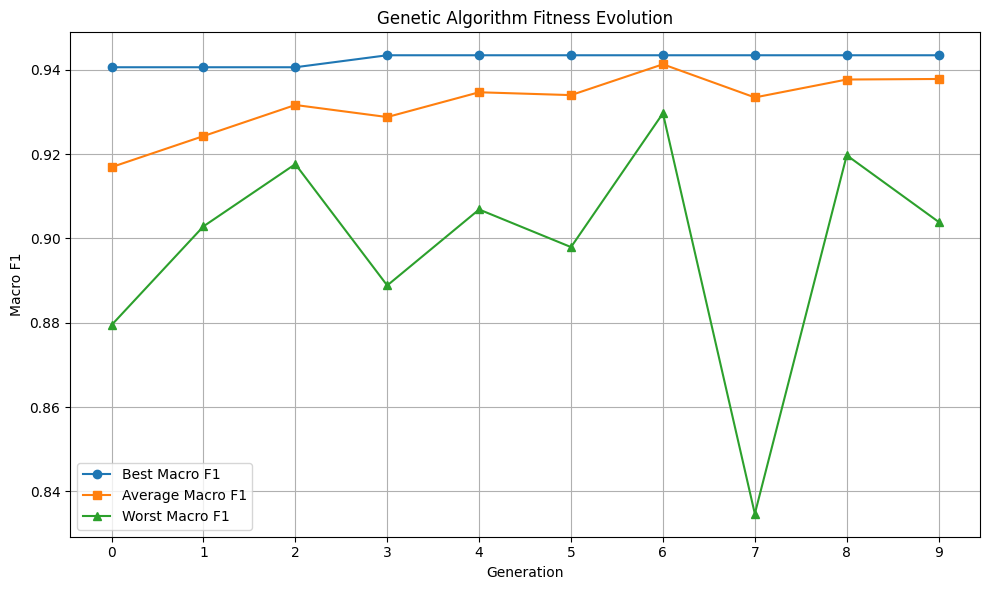

Fitness plot saved to: /kaggle/working/outputs/genetic_algorithm/experiment_01/fitness_evolution.png


In [12]:
plt.figure(figsize=(10, 6))
plt.plot(history_df["generation"], history_df["best_fitness"], marker="o", label="Best Macro F1")
plt.plot(history_df["generation"], history_df["average_fitness"], marker="s", label="Average Macro F1")
plt.plot(history_df["generation"], history_df["worst_fitness"], marker="^", label="Worst Macro F1")
plt.xlabel("Generation")
plt.ylabel("Macro F1")
plt.title("Genetic Algorithm Fitness Evolution")
plt.xticks(history_df["generation"])
plt.grid(True)
plt.legend()
plt.tight_layout()

fitness_plot_path = OUTPUT_DIR / "fitness_evolution.png"
plt.savefig(fitness_plot_path, dpi=300)
plt.show()
print("Fitness plot saved to:", fitness_plot_path)

## 13. Plot Population Diversity

Diversity is exact prompt-string uniqueness, not semantic similarity.

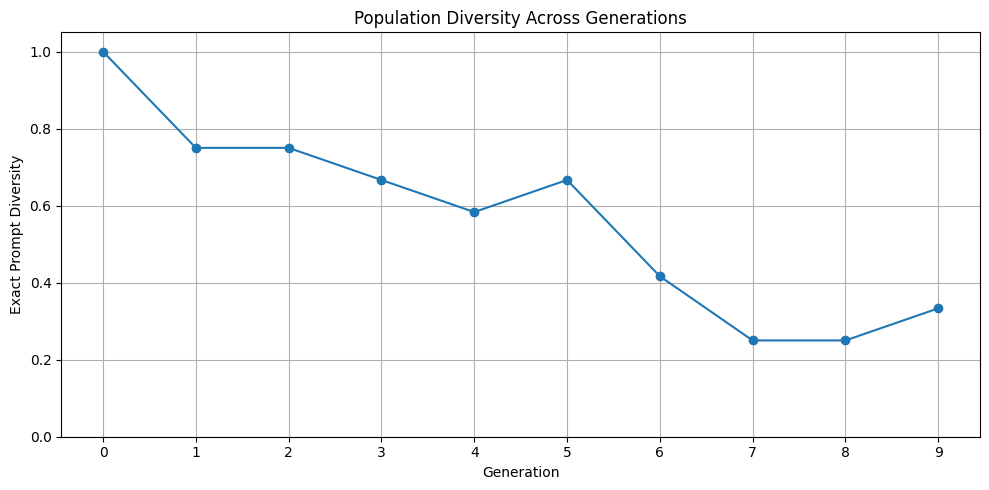

Diversity plot saved to: /kaggle/working/outputs/genetic_algorithm/experiment_01/population_diversity.png


In [13]:
plt.figure(figsize=(10, 5))
plt.plot(history_df["generation"], history_df["diversity"], marker="o")
plt.xlabel("Generation")
plt.ylabel("Exact Prompt Diversity")
plt.title("Population Diversity Across Generations")
plt.xticks(history_df["generation"])
plt.ylim(0, 1.05)
plt.grid(True)
plt.tight_layout()

diversity_plot_path = OUTPUT_DIR / "population_diversity.png"
plt.savefig(diversity_plot_path, dpi=300)
plt.show()
print("Diversity plot saved to:", diversity_plot_path)

## 14. Save Experiment Configuration

In [14]:
experiment_config = {
    "experiment_name": "genetic_algorithm_experiment_01",
    "dataset": "SST-2",
    "optimization_split": "opt",
    "optimization_sample_size": N_OPT,
    "sampling_seed": SEED,
    "model_id": llm.model_id,
    "model_revision": model_config.revision,
    "inference_config": llm.inference_config,
    "gpu_name": GPU_NAME,
    "cuda_version": CUDA_VERSION,
    "pytorch_version": torch.__version__,
    "population_size": POPULATION_SIZE,
    "generations_requested": GENERATIONS,
    "generations_evaluated": len(history_df),
    "elite_count": ELITE_COUNT,
    "tournament_size": TOURNAMENT_SIZE,
    "crossover_rate": CROSSOVER_RATE,
    "mutation_rate": MUTATION_RATE,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "fitness_metric": "Macro F1",
    "number_of_manual_seed_prompts": len(seed_prompts),
    "random_seed": SEED,
    "execution_time_seconds": round(experiment_duration, 2),
}

config_path = OUTPUT_DIR / "experiment_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=4, default=str)

print("Experiment configuration saved:", config_path)

Experiment configuration saved: /kaggle/working/outputs/genetic_algorithm/experiment_01/experiment_config.json


# Part B: Manual vs Evolved Prompt Comparison

## 15. Helper Functions

`evaluate_prompt` returns a dict with a `"metrics"` entry. Metric key names differ across
code (`f1_macro` vs `macro_f1`), so one helper reads them with fallbacks.
Every comparison uses the same helper, so the tables are consistent.

In [15]:
def pick(d, *keys, default=None):
    """Return the first key found in dict d."""
    for k in keys:
        if k in d:
            return d[k]
    if default is not None:
        return default
    raise KeyError(f"None of {keys} found. Available keys: {list(d.keys())}")


def evaluate_on(prompt, texts, gold, cache, split_name):
    """Evaluate one prompt with the project's evaluation module."""
    return evaluate_prompt(
        prompt=prompt,
        examples=texts,
        labels=gold,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache,
        batch_size=None,
        split_name=split_name,
    )


def metrics_row(name, prompt_type, res):
    m = res["metrics"]
    return {
        "prompt_name": name,
        "type": prompt_type,
        "macro_f1": pick(m, "f1_macro", "macro_f1"),
        "accuracy": m["accuracy"],
        "precision_macro": pick(m, "precision_macro", "macro_precision"),
        "recall_macro": pick(m, "recall_macro", "macro_recall"),
        "n_invalid": m["n_invalid"],
        "invalid_rate": m["invalid_rate"],
    }


print("Helpers defined.")

Helpers defined.


## 16. Optimization-Set Comparison

All 8 manual prompts and the best evolved prompt are evaluated on the same 1,000
optimization examples. Predictions already in `prediction_cache` are reused.
A dictionary maps each name to its prompt, so no prompt is recovered by string parsing later.

In [16]:
manual_prompts = {f"Manual {i}": p for i, p in enumerate(seed_prompts, start=1)}
EVOLVED_NAME = f"Best evolved (Gen {best_individual.generation})"

all_prompts = dict(manual_prompts)
all_prompts[EVOLVED_NAME] = best_individual.prompt

opt_results = {}   # keep full results (may contain per-example predictions)
rows = []

for name, prompt in all_prompts.items():
    res = evaluate_on(prompt, examples, labels, prediction_cache, "opt")
    opt_results[name] = res
    rows.append(metrics_row(name, "Evolved" if name == EVOLVED_NAME else "Manual", res))

comparison_df = (
    pd.DataFrame(rows)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df)

comparison_path = OUTPUT_DIR / "prompt_comparison_opt.csv"
comparison_df.to_csv(comparison_path, index=False)
print("Saved:", comparison_path)

,prompt_name,type,macro_f1,accuracy,precision_macro,recall_macro,n_invalid,invalid_rate
0,Best evolved (Gen 3),Evolved,0.943434,0.944,0.942249,0.945118,0,0.000
1,Manual 3,Manual,0.936426,0.937,0.935091,0.938610,0,0.000
2,Manual 7,Manual,0.921056,0.918,0.923812,0.923231,7,0.007
3,Manual 8,Manual,0.920622,0.921,0.919927,0.925449,0,0.000
4,Manual 1,Manual,0.918697,0.919,0.918667,0.924362,0,0.000
5,Manual 6,Manual,0.916579,0.917,0.915773,0.921159,0,0.000
6,Manual 5,Manual,0.909792,0.910,0.911325,0.916768,0,0.000
7,Manual 2,Manual,0.893451,0.889,0.903544,0.898421,10,0.010
8,Manual 4,Manual,0.879439,0.879,0.890240,0.890401,1,0.001


Saved: /kaggle/working/outputs/genetic_algorithm/experiment_01/prompt_comparison_opt.csv


## 17. Best Manual vs Evolved (Optimization Set)

In [17]:
best_manual = comparison_df[comparison_df["type"] == "Manual"].iloc[0]
evolved = comparison_df[comparison_df["type"] == "Evolved"].iloc[0]

best_manual_name = best_manual["prompt_name"]
best_manual_prompt = manual_prompts[best_manual_name]   # direct lookup

opt_difference = float(evolved["macro_f1"] - best_manual["macro_f1"])

print("=" * 55)
print("OPTIMIZATION SET: BEST MANUAL VS EVOLVED")
print("=" * 55)
print(f"Best manual prompt:   {best_manual_name}")
print(f"Best manual Macro F1: {best_manual['macro_f1']:.4f}")
print(f"Evolved Macro F1:     {evolved['macro_f1']:.4f}")
print(f"Difference:           {opt_difference:+.4f} ({opt_difference * 100:+.2f} points)")

if opt_difference > 0:
    print("\nThe evolved prompt scored higher on the optimization set.")
elif opt_difference < 0:
    print("\nThe best manual prompt scored higher on the optimization set.")
else:
    print("\nBoth prompts achieved the same Macro F1.")

print("\nBest manual prompt text:\n", best_manual_prompt)
print("\nNote: the evolved prompt was selected on this set, so this comparison is optimistic.")
print("The validation comparison below is the fairer one.")

OPTIMIZATION SET: BEST MANUAL VS EVOLVED
Best manual prompt:   Manual 3
Best manual Macro F1: 0.9364
Evolved Macro F1:     0.9434
Difference:           +0.0070 (+0.70 points)

The evolved prompt scored higher on the optimization set.

Best manual prompt text:
 Look for praise, enthusiasm and approval (positive) versus complaints, disappointment and criticism (negative). Weigh the overall tone of the text, then output exactly one word: positive or negative.

Note: the evolved prompt was selected on this set, so this comparison is optimistic.
The validation comparison below is the fairer one.


## 18. Load Validation Data

Validation is used only to compare the two prompts already selected on the optimization set.
It is not used to modify the GA or select new prompts.

In [18]:
validation_df = splits.val.copy()

if "sentence" in validation_df.columns:
    val_text_col = "sentence"
elif "text" in validation_df.columns:
    val_text_col = "text"
else:
    raise ValueError(f"Text column not found. Columns: {list(validation_df.columns)}")

if "label" not in validation_df.columns:
    raise ValueError(f"Label column not found. Columns: {list(validation_df.columns)}")

val_examples = validation_df[val_text_col].astype(str).tolist()
val_labels = validation_df["label"].astype(int).tolist()

print("Validation examples:", len(val_examples))
print("\nClass distribution:")
print(validation_df["label"].value_counts().sort_index())

Validation examples: 13468

Class distribution:
label
0    5955
1    7513
Name: count, dtype: int64


## 19. Evaluate the Two Selected Prompts on Validation

A separate cache is used for validation. This is the slowest step of Part B (a few minutes).

In [19]:
validation_cache = PredictionCache()

print(f"Evaluating best manual prompt ({best_manual_name}) on validation...")
manual_val_res = evaluate_on(best_manual_prompt, val_examples, val_labels, validation_cache, "val")

print("Evaluating best evolved prompt on validation...")
evolved_val_res = evaluate_on(best_individual.prompt, val_examples, val_labels, validation_cache, "val")

print("\nValidation evaluation completed.")

Evaluating best manual prompt (Manual 3) on validation...
Evaluating best evolved prompt on validation...

Validation evaluation completed.


## 20. Validation Results

In [20]:
validation_comparison = pd.DataFrame([
    metrics_row(f"Best manual ({best_manual_name})", "Manual", manual_val_res),
    metrics_row(EVOLVED_NAME, "Evolved", evolved_val_res),
])

display(validation_comparison)

validation_comparison.to_csv(OUTPUT_DIR / "prompt_comparison_validation.csv", index=False)

manual_val_f1 = float(validation_comparison.loc[0, "macro_f1"])
evolved_val_f1 = float(validation_comparison.loc[1, "macro_f1"])
val_difference = evolved_val_f1 - manual_val_f1

print("=" * 55)
print("VALIDATION SET: BEST MANUAL VS EVOLVED")
print("=" * 55)
print(f"Best manual Macro F1: {manual_val_f1:.4f}")
print(f"Evolved Macro F1:     {evolved_val_f1:.4f}")
print(f"Difference:           {val_difference:+.4f} ({val_difference * 100:+.2f} points)")

if val_difference > 0:
    print("\nThe evolved prompt scored higher on validation.")
elif val_difference < 0:
    print("\nThe best manual prompt scored higher on validation.")
else:
    print("\nBoth prompts achieved the same validation Macro F1.")

,prompt_name,type,macro_f1,accuracy,precision_macro,recall_macro,n_invalid,invalid_rate
0,Best manual (Manual 3),Manual,0.926151,0.926864,0.924964,0.927918,0,0.000000
1,Best evolved (Gen 3),Evolved,0.933148,0.933398,0.932713,0.933809,13,0.000965


VALIDATION SET: BEST MANUAL VS EVOLVED
Best manual Macro F1: 0.9262
Evolved Macro F1:     0.9331
Difference:           +0.0070 (+0.70 points)

The evolved prompt scored higher on validation.


## 21. Plot Validation Comparison

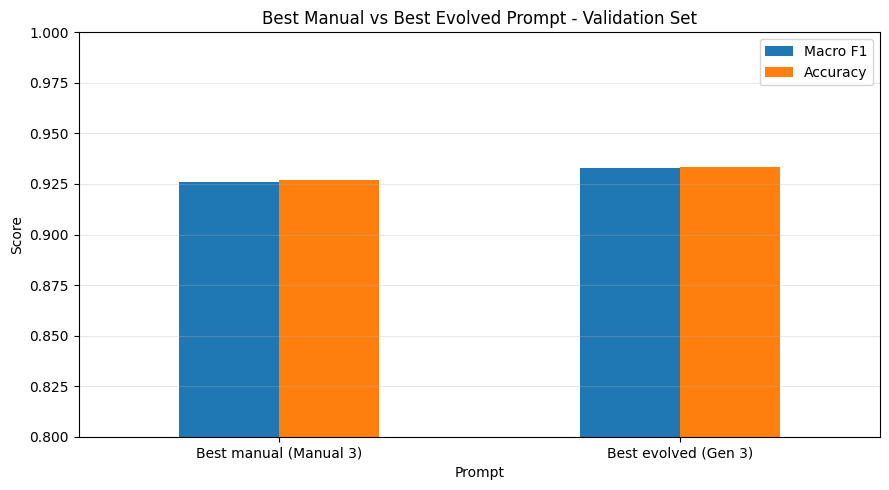

In [21]:
plot_df = validation_comparison.set_index("prompt_name")[["macro_f1", "accuracy"]]

ax = plot_df.plot(kind="bar", figsize=(9, 5), ylim=(0.8, 1.0), rot=0)
ax.set_title("Best Manual vs Best Evolved Prompt - Validation Set")
ax.set_ylabel("Score")
ax.set_xlabel("Prompt")
ax.legend(["Macro F1", "Accuracy"])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "validation_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 22. Paired Significance Test (McNemar, exact)

With about 0.8 points of standard error on 1,000 examples, a small gap may be noise.
Both prompts are evaluated on the same examples, so a paired test on per-example
correctness is appropriate. The test is run on validation, where neither prompt was selected.

If the evaluation module does not return per-example predictions, this cell reports the
available keys and skips the test without failing.

In [22]:
from scipy.stats import binomtest

LABEL_MAP = {"positive": 1, "negative": 0}


def find_predictions(res):
    for key in ["predictions", "preds", "y_pred", "parsed_predictions", "parsed"]:
        if key in res and res[key] is not None and len(res[key]) > 0:
            return res[key]
    return None


def correctness(preds, gold):
    out = []
    for p, y in zip(preds, gold):
        if isinstance(p, str):
            p = LABEL_MAP.get(p.strip().lower(), None)
        out.append(p == y)   # invalid or None counts as incorrect
    return np.array(out)


mcnemar_result = None
p_manual = find_predictions(manual_val_res)
p_evolved = find_predictions(evolved_val_res)

if p_manual is None or p_evolved is None or len(p_manual) != len(val_labels) or len(p_evolved) != len(val_labels):
    print("Per-example predictions not found in evaluate_prompt output. Test skipped.")
    print("Available keys:", list(evolved_val_res.keys()))
else:
    c_manual = correctness(p_manual, val_labels)
    c_evolved = correctness(p_evolved, val_labels)

    only_evolved = int(np.sum(c_evolved & ~c_manual))   # evolved right, manual wrong
    only_manual = int(np.sum(~c_evolved & c_manual))    # manual right, evolved wrong
    n_discordant = only_evolved + only_manual

    p_value = 1.0 if n_discordant == 0 else float(
        binomtest(only_evolved, n_discordant, 0.5).pvalue
    )

    mcnemar_result = {
        "only_evolved_correct": only_evolved,
        "only_manual_correct": only_manual,
        "p_value": p_value,
    }

    print("Evolved correct, manual wrong:", only_evolved)
    print("Manual correct, evolved wrong:", only_manual)
    print(f"Exact McNemar p-value: {p_value:.4f}")
    print("Significant at 0.05." if p_value < 0.05 else "Not significant at 0.05.")

Evolved correct, manual wrong: 236
Manual correct, evolved wrong: 148
Exact McNemar p-value: 0.0000
Significant at 0.05.


## 23. Final Summary, Verdict and ZIP

The verdict is computed from the results, not written in advance.

In [23]:
from datetime import datetime

if mcnemar_result is not None and mcnemar_result["p_value"] < 0.05:
    sig_text = "statistically significant (McNemar p < 0.05)"
elif mcnemar_result is not None:
    sig_text = "not statistically significant (McNemar p >= 0.05)"
else:
    sig_text = "significance not tested"

if val_difference > 0:
    verdict = f"Evolved prompt higher on validation by {val_difference * 100:.2f} points; {sig_text}."
elif val_difference < 0:
    verdict = f"Best manual prompt higher on validation by {-val_difference * 100:.2f} points; {sig_text}."
else:
    verdict = f"Equal validation Macro F1; {sig_text}."

final_summary = {
    "experiment": "Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis",
    "algorithm": "Genetic Algorithm",
    "dataset": "SST-2",
    "model": llm.model_id,
    "model_revision": model_config.revision,
    "optimization": {
        "number_of_examples": len(examples),
        "population_size": POPULATION_SIZE,
        "generations": GENERATIONS,
        "elite_count": ELITE_COUNT,
        "tournament_size": TOURNAMENT_SIZE,
        "crossover_rate": CROSSOVER_RATE,
        "mutation_rate": MUTATION_RATE,
        "random_seed": SEED,
    },
    "best_evolved_prompt": {
        "prompt": best_individual.prompt,
        "individual_id": best_individual.id,
        "generation": best_individual.generation,
        "macro_f1_opt": float(evolved["macro_f1"]),
        "accuracy_opt": float(evolved["accuracy"]),
    },
    "best_manual_prompt": {
        "name": best_manual_name,
        "prompt": best_manual_prompt,
        "macro_f1_opt": float(best_manual["macro_f1"]),
        "accuracy_opt": float(best_manual["accuracy"]),
    },
    "optimization_comparison": {"macro_f1_difference": opt_difference},
    "validation_comparison": {
        "n_examples": len(val_examples),
        "best_manual_macro_f1": manual_val_f1,
        "evolved_macro_f1": evolved_val_f1,
        "macro_f1_difference": val_difference,
        "best_manual_accuracy": float(validation_comparison.loc[0, "accuracy"]),
        "evolved_accuracy": float(validation_comparison.loc[1, "accuracy"]),
        "mcnemar": mcnemar_result,
    },
    "verdict": verdict,
    "limitations": [
        "Single GA run with seed 42.",
        "Standard error of about 0.8 points on 1,000 examples.",
        "Some crossover/mutation attempts returned a parent prompt after exhausting retries.",
        "Diversity measures exact prompt-string uniqueness, not semantic diversity.",
        "The final test set was not used.",
    ],
    "created_at": datetime.now().isoformat(),
}

summary_path = OUTPUT_DIR / "final_experiment_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(final_summary, f, indent=4, ensure_ascii=False, default=str)

print("=" * 65)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 65)
print("Best evolved prompt:\n", best_individual.prompt)
print(f"\nOptimization: manual {best_manual['macro_f1']:.4f} | evolved {evolved['macro_f1']:.4f}")
print(f"Validation:   manual {manual_val_f1:.4f} | evolved {evolved_val_f1:.4f}")
print("\nVerdict:", verdict)

# Create the final ZIP with every output file.
import shutil
from IPython.display import FileLink

ZIP_PATH = "/kaggle/working/genetic_algorithm_experiment_01"
shutil.make_archive(ZIP_PATH, "zip", root_dir=str(OUTPUT_DIR))

print("\nFiles in archive:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

display(FileLink(ZIP_PATH + ".zip"))

FINAL EXPERIMENT SUMMARY
Best evolved prompt:
 Is the text positive or negative? Answer with exactly one word: positive or negative.

Optimization: manual 0.9364 | evolved 0.9434
Validation:   manual 0.9262 | evolved 0.9331

Verdict: Evolved prompt higher on validation by 0.70 points; statistically significant (McNemar p < 0.05).

Files in archive:
- best_individual.json
- best_prompt.txt
- experiment_config.json
- final_experiment_summary.json
- fitness_evolution.png
- history.csv
- history.json
- population_diversity.png
- prompt_comparison_opt.csv
- prompt_comparison_validation.csv
- validation_comparison.png


/kaggle/working/genetic_algorithm_experiment_01.zip